### Who benefits from grocery offer?

the bis is deciding whom to offer a $5 grocery discount. Sending it to frequent shoppers is easy. But some would have bought anyway. We want to find customers whose spending actually increases because of the offer.

One row represents one customer with a complete 30-day follow-up. We randomly assign the offer to 20% of 6,000 eligible customers and measure merchandise spending before campaign costs. The effect is for offering the discount, whether or not someone redeems it.

Meta-learners complement this randomized study; they do not replace randomization. EconML organizes the models for all three. The outcome models use boosted trees: a sequence of small trees that correct earlier prediction errors. X uses Ridge, a linear model with a penalty that discourages unstable coefficients, to learn a smoother effect pattern.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyClassifier
from econml.metalearners import SLearner, TLearner, XLearner

# Case-study customers. All inputs precede the offer.
rng = np.random.default_rng(42)
n = 6000
X = np.column_stack([rng.uniform(0, 5, n), rng.uniform(0, 1, n)])
T = rng.binomial(1, 0.20, n)  # Randomly offer the coupon to 20%.
true_effect = 10 - 2 * X[:, 0]  # Teaching truth; never passed to a learner.
Y = 60 + 5 * X[:, 0] + 8 * X[:, 1] + T * true_effect + rng.normal(0, 8, n)
data = pd.DataFrame({"prior_orders": X[:, 0], "prior_discount_share": X[:, 1],
                     "offered": T, "spend_30d": Y})
# Disjoint customers: fit models, set a rule, then evaluate once.
train = np.arange(3000)
validation = np.arange(3000, 4500)
test = np.arange(4500, 6000)

def outcome_model():
    return GradientBoostingRegressor(n_estimators=80, max_depth=2,
                                     min_samples_leaf=30, random_state=7)

def fit_learners():
    learners = {
        "S": SLearner(overall_model=outcome_model()),
        "T": TLearner(models=outcome_model()),
        # Treatment was randomized. The classifier learns one constant share.
        # Ridge fits a smooth effect pattern from the estimated effects.
        "X": XLearner(models=outcome_model(), cate_models=Ridge(alpha=1),
                      propensity_model=DummyClassifier(strategy="prior")),
    }
    for learner in learners.values():
        learner.fit(Y[train], T[train], X=X[train])
    return learners

#### 1. Inspect the customers and protect the test sample

First check what a row means and whether we have customers in both arms. The two model inputs are average monthly orders and the share of earlier orders using discounts. Both precede assignment. Coupon redemption would be a bad input because the offer itself can change it.

We reserve separate customers for training, choosing the targeting threshold, and a final test. Every cell includes its own editable setup so it runs independently. The data setup's known effect is kept out of the models.

 prior_orders  prior_discount_share  offered  spend_30d
         3.87                  0.46        0      83.94
         2.19                  0.12        0      63.78
         4.29                  0.57        0     101.63
         3.49                  0.16        1      96.50
         0.47                  0.06        0      46.25
         4.88                  0.50        0      89.79


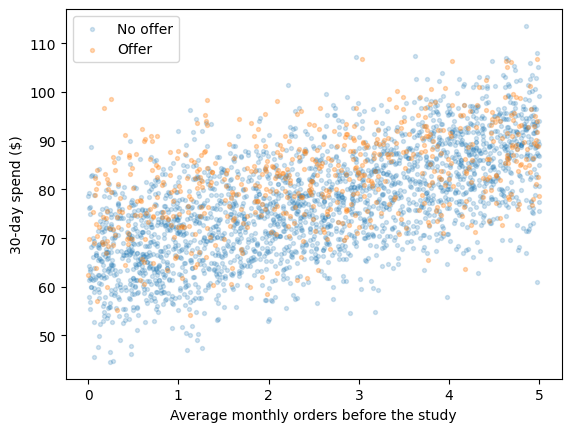

In [8]:
# Check the unit, available inputs, and assignment counts before fitting.
print(data.head(6).round(2).to_string(index=False))
rows = []
for name, ids in [("Training", train), ("Validation", validation), ("Test", test)]:
    rows.append({"Split": name, "Customers": len(ids),
                 "Offered": int(T[ids].sum()), "No offer": int((1-T[ids]).sum())})
# Plot observed outcomes, not individual effects set in the data setup.
plt.scatter(X[train][T[train]==0, 0], Y[train][T[train]==0], s=8, alpha=.2, label="No offer")
plt.scatter(X[train][T[train]==1, 0], Y[train][T[train]==1], s=8, alpha=.3, label="Offer")
plt.xlabel("Average monthly orders before the study")
plt.ylabel("30-day spend ($)")
plt.legend()

In [10]:
rows

[{'Split': 'Training', 'Customers': 3000, 'Offered': 580, 'No offer': 2420},
 {'Split': 'Validation', 'Customers': 1500, 'Offered': 318, 'No offer': 1182},
 {'Split': 'Test', 'Customers': 1500, 'Offered': 312, 'No offer': 1188}]

In [12]:
df = pd.DataFrame(rows)
print(df.to_string(index=False))

     Split  Customers  Offered  No offer
  Training       3000      580      2420
Validation       1500      318      1182
      Test       1500      312      1188


The training sample contains 580 offered and 2,420 unoffered customers. That imbalance is intentional, not evidence that randomization failed. The test set keeps another 312 offered customers untouched.

The scatter shows that people with more prior orders generally spend more. It does not tell us which profiles benefit most from the offer. That requires predicting both outcomes for the same profile.

#### 2. Fit one outcome model, then two

Start with S and T on the same training customers. EconML's effect method does the two-prediction subtraction. We use three customer profiles as a readable check, holding prior discount use at 50%.

In [17]:
# S uses one model; T estimates a separate outcome model for each arm.
s = SLearner(overall_model=outcome_model())
t = TLearner(models=outcome_model())
s.fit(Y[train], T[train], X=X[train])
t.fit(Y[train], T[train], X=X[train])
# Hold discount history constant while comparing customer profiles.
profiles = np.array([[0.5, .5], [2.5, .5], [4.5, .5]])
effects = pd.DataFrame({
    "Prior orders": profiles[:, 0],
    "S: predicted offer effect ($)": s.effect(profiles),
    "T: predicted offer effect ($)": t.effect(profiles),
}).round(2)

print(effects.to_string(index=False))

 Prior orders  S: predicted offer effect ($)  T: predicted offer effect ($)
          0.5                           8.30                          10.42
          2.5                           4.24                           6.22
          4.5                           1.41                           1.13


For a customer averaging 0.5 earlier orders per month, S predicts $8.30 in extra spending and T predicts $10.42. At 4.5 earlier orders, their predictions fall to $1.41 and $1.13. Both suggest that frequent shoppers need the offer less, even though they spend more overall.

These are predicted increases in 30-day spending, not total spending. S and T differ because one shares a model and the other fits each arm separately. Do not pick a winner from three plausible-looking predictions. Next we check the effect pattern outside training.

#### 3. Add X and check the effect pattern
X adds a modeling step for the estimated effects. Here we deliberately use a smooth linear effect model because the teaching example has a simple pattern. With real data, we would check that choice using separate validation data and a suitable causal evaluation, not hidden simulation truth.

We set the targeting threshold at the median validation score. That selects roughly half of future eligible customers. The exact test share can differ.

Frozen targeting threshold: predicted lift of $5.08


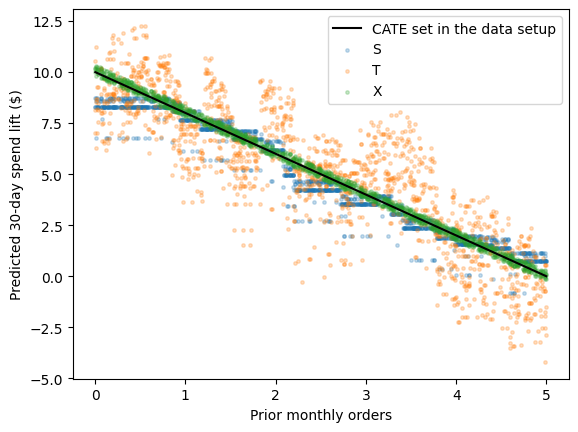

In [19]:
learners = fit_learners()
# X is chosen in advance for this walkthrough, not after inspecting test results.
# A fresh validation set sets the threshold for the highest-scored half.
validation_scores = learners["X"].effect(X[validation])
threshold = np.median(validation_scores)
print(f"Frozen targeting threshold: predicted lift of ${threshold:.2f}")
rows = []
for name, learner in learners.items():
    predicted = learner.effect(X[validation])
    rows.append({"Learner": name, "Mean predicted lift ($)": predicted.mean(),
                 "CATE RMSE: simulation only ($)": np.sqrt(np.mean((predicted-true_effect[validation])**2))})
# Known CATE exists only because we specified the data-generating process.
order = np.argsort(X[validation, 0])
plt.plot(X[validation][order,0], true_effect[validation][order], color="black", label="CATE set in the data setup")
for name, learner in learners.items():
    plt.scatter(X[validation,0], learner.effect(X[validation]), s=6, alpha=.25, label=name)
plt.xlabel("Prior monthly orders")
plt.ylabel("Predicted 30-day spend lift ($)")
plt.legend()

In [20]:
# pd.DataFrame(rows).round(2)

df3 = pd.DataFrame(rows)
print(df3.to_string(index=False))

Learner  Mean predicted lift ($)  CATE RMSE: simulation only ($)
      S                 4.757492                        0.727140
      T                 5.038303                        1.773845
      X                 5.103651                        0.156711


The supplied example gives CATE errors of about $0.73 for S, $1.77 for T, and $0.16 for X on validation customers. Lower means closer to the known effect set in the data setup. X benefits here from a simple effect pattern and a larger control group. This is one worked example, not a leaderboard for real studies.

In real data, we cannot calculate that error because we do not know each profile's true effect. We use it here only to teach the mechanism. The X targeting rule was chosen in advance; its validation threshold is about $5.08 of predicted lift. We now freeze it and test whether the selected group actually benefits.

#### 4. Test the frozen group and make the decision

Now open the test outcomes once. Because the rule uses only earlier characteristics and models fitted elsewhere, treatment is still randomized inside the selected group.

Our primary question is whether the offer increases spending for that group. We use a Welch comparison of the two randomized arms, with a 95% interval and a 5% significance level chosen before reading the result. This assumes independent customers and enough observations in each arm. Shared households would require a design and uncertainty calculation that account for them.

In [25]:
learners = fit_learners()
threshold = np.median(learners["X"].effect(X[validation]))
# Freeze the rule without looking at test outcomes or treatment assignments.
selected = learners["X"].effect(X[test]) >= threshold

def comparison(mask):
    ids = test[mask]
    treated, control = Y[ids][T[ids]==1], Y[ids][T[ids]==0]
    effect = treated.mean() - control.mean()
    a, b = treated.var(ddof=1)/len(treated), control.var(ddof=1)/len(control)
    se = np.sqrt(a+b)
    df = (a+b)**2/(a*a/(len(treated)-1)+b*b/(len(control)-1))
    margin = stats.t.ppf(.975, df)*se
    p = 2*stats.t.sf(abs(effect/se), df)
    return {"Offered":len(treated), "No offer":len(control),
            "Offer mean ($)":treated.mean(), "Control mean ($)":control.mean(),
            "Lift ($)":effect, "95% low ($)":effect-margin,
            "95% high ($)":effect+margin, "p-value":p}


In [26]:
# Primary check: does the frozen selected group benefit?
# Other rows are context, not additional chances to find significance.
results = pd.DataFrame(
    [
        comparison(selected),
        comparison(~selected),
        comparison(np.ones(len(test), dtype=bool)),
    ],
    index=["Selected: primary", "Not selected: exploratory", "All test customers"],
)
print(f"Selected {selected.sum()} of {len(test)} test customers.")

p_values = results["p-value"].map("{:.3g}".format)
results = results.round(4)
results["p-value"] = p_values

print(results.to_string())

Selected 775 of 1500 test customers.
                           Offered  No offer  Offer mean ($)  Control mean ($)  Lift ($)  95% low ($)  95% high ($)   p-value
Selected: primary              155       620         77.5151           71.0075    6.5075       5.1205        7.8945  8.51e-18
Not selected: exploratory      157       568         84.9483           82.6104    2.3379       0.7536        3.9221   0.00398
All test customers             312      1188         81.2555           76.5550    4.7005       3.5256        5.8754  2.01e-14


The frozen rule selects 775 test customers. Their observed spending averages $77.52 with the offer versus $71.01 without it: a $6.51 increase per selected customer over 30 days. The 95% interval is $5.12 to $7.89. The primary test rejects zero lift at the prespecified 5% significance level.

This interval describes the average offer effect in the selected group, conditional on the learned rule. It is not an interval for an individual's effect or for the model's accuracy. The independent test and random assignment justify the group comparison; simply bootstrapping the model's predictions would not do that.

The other rows provide context: the estimated lift is $2.34 outside the selected group and $4.70 across all test customers. Comparing point estimates alone is not a formal test that the selected group benefits more. These are exploratory comparisons, not extra primary tests.

Recommendation: the selected group shows a credible spending response, but spending is not profit. Before launching targeting, include redemption costs, merchandise margin, and guardrails such as unsubscribes and longer-term purchasing. Then compare the frozen targeting policy with the current offer policy in a new randomized test. This analysis does not yet establish that targeting is the most profitable policy.